# 12 · Resultados de D-06 y D-07

**Qué contesta.** La pregunta del proyecto (resumen de WAIMLAp): ¿en qué medida la MLCA mejora la precisión y la
robustez de la segmentación RGB-D frente a fusiones convencionales cuando la profundidad es ruidosa, incompleta o
falta? D-06 y D-07 separan tres factores, cada configuración con 3 semillas:

| Factor | Niveles |
|---|---|
| Operador de fusión | suma (proyección 1×1 iniciada en cero) · MLCA (atención cruzada lineal, con máscara de validez binaria o sin ella) |
| Lugar | solo en la cabeza, con los dos codificadores congelados · también a la entrada de la última etapa del color, que se ajusta |
| Entrenamiento | sin o con *modality dropout* (0.3) |

**Cómo se reproduce.** Solo lee `runs/rgbd/` (el `resultado.json` de cada corrida, los criterios y los diagnósticos
guardados) y `runs/coste/`: no entrena ni usa la GPU, y corre en segundos. Las decisiones, las predicciones
escritas antes de cada experimento y el criterio están en `DECISIONES.md` (D-06 y D-07) y en `predicciones/`.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RUNS = RAIZ / "runs" / "rgbd"


def cargar_corridas():
    # Corridas del test: se excluyen la validación, las pruebas de humo, el control de D-06 y las combinaciones.
    filas, clases = [], None
    for f in sorted(RUNS.glob("*/resultado.json")):
        nombre = f.parent.name
        if nombre.startswith(("val_", "control_")) or nombre.endswith("_humo") or nombre == "combinaciones":
            continue
        r = json.loads(f.read_text(encoding="utf-8"))
        for cond, v in r["resultados"].items():
            filas.append({"exp": r["exp"], "lr": r["lr"], "semilla": r["semilla"], "cond": cond,
                          "miou": v["miou"], "iou_clase": v.get("iou_clase")})
        clases = r.get("clases") or clases
    return pd.DataFrame(filas), clases


res, CLASES = cargar_corridas()
assert res.groupby("exp")["lr"].nunique().max() == 1          # una sola lr por experimento en el test
assert (res.groupby(["exp", "cond"]).size() == 3).all()      # 3 semillas en cada condición evaluada
LR = res.groupby("exp")["lr"].first()


def m(exp, cond="completa"):
    v = res[(res.exp == exp) & (res.cond == cond)].miou
    return v.mean() if len(v) else np.nan


def mde(exp, cond):
    v = res[(res.exp == exp) & (res.cond == cond)].miou
    return f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" if len(v) else "—"


print(f"{res.exp.nunique()} experimentos, {res.groupby(['exp', 'semilla']).ngroups} corridas de test, "
      f"{res.cond.nunique()} condiciones de profundidad")

24 experimentos, 72 corridas de test, 13 condiciones de profundidad


## 1. Protocolo

- **Datos.** NYUv2, partición oficial: 795 imágenes de entrenamiento y 654 de test; 40 clases; mIoU.
- **Semillas y lr.** 3 semillas por configuración. La lr se elige en una validación por escenas (15 % de las escenas
  de entrenamiento, semilla 0; si la mejor queda en un extremo de la grilla, se prueba el siguiente valor) y el test
  se evalúa una sola vez por configuración (anexo A).
- **Profundidad.** Se entrena siempre con la profundidad rellenada. Al evaluar, pasa por estas condiciones:

| Condición | Qué se hace |
|---|---|
| completa | la profundidad rellenada, sin huecos |
| cruda | la del sensor (`rawDepths`), con sus huecos reales |
| aleatoria r | el r % de los píxeles a cero (Liao et al., 2025); r = 100 es «sin» |
| regiones s | rectángulos a cero con severidad s (corrupción *hole* de GeomPrompt) |
| ruido σ | ruido gaussiano de σ cm; la máscara no lo ve, porque los valores siguen siendo válidos |
| sin | ninguna profundidad válida |

- **Criterio** (escrito antes de abrir los resultados): «aporta» si la diferencia pareada es positiva, su IC 95 % por
  remuestreo de imágenes excluye el 0 y el signo se repite en las 3 semillas; «perjudica», lo simétrico; «no aporta»
  si |dif.| < 0.3 y el IC incluye el 0; si no, «no concluyente». Holm sobre las condiciones de cada contraste.
- **Derivados sin entrenar.** Sin dropout, la máscara no actúa al entrenar (la profundidad rellenada no tiene
  huecos), así que E3c y E3e son los pesos de E4c y E4e evaluados sin máscara: el mismo modelo, y una diferencia
  pareada limpia.

## 2. Todos los resultados

Test, media ± DE de 3 semillas, mIoU (%). En negrita, el mejor de cada grupo (sin contar solo color).

In [2]:
GRUPOS = [
    ("Codificadores congelados: se entrenan la fusión y la cabeza", [
        ("E1", "solo color"),
        ("E2c", "suma"),
        ("E3c", "MLCA sin máscara (derivado de E4c)"),
        ("E4c", "MLCA con máscara"),
        ("E2cd", "suma + dropout"),
        ("E3cd", "MLCA sin máscara + dropout"),
        ("E4cd", "MLCA con máscara + dropout"),
    ]),
    ("Última etapa del color ajustada", [
        ("E1u", "solo color"),
        ("E10", "suma en la cabeza"),
        ("E11", "suma en la cabeza y en el codificador"),
        ("E3e", "E11 con MLCA sin máscara en el codificador (derivado de E4e)"),
        ("E4e", "E11 con MLCA con máscara en el codificador"),
        ("E11d", "E11 + dropout"),
        ("E4ed", "E4e + dropout"),
    ]),
]
SOLO_COLOR = {"E1", "E1u"}
COND = [("completa", "completa"), ("cruda", "cruda"), ("aleatoria_50", "50 % aleatorio"),
        ("regiones", "regiones 0.5"), ("ruido_50cm", "ruido 50 cm"), ("sin", "sin profundidad")]


def tabla(grupos, cond):
    L = ["| Exp. | Qué es | lr | " + " | ".join(t for _, t in cond) + " |", "|---|---|---|" + "---|" * len(cond)]
    for titulo, filas in grupos:
        L.append(f"| **{titulo}** |" + " |" * (len(cond) + 2))
        mejor = {c: max(m(e, c) for e, _ in filas if e not in SOLO_COLOR) for c, _ in cond}
        for e, que in filas:
            celdas = []
            for c, _ in cond:
                s = mde(e, c)
                celdas.append(f"**{s}**" if e not in SOLO_COLOR and np.isclose(m(e, c), mejor[c]) else s)
            L.append(f"| {e} | {que} | {LR[e]:g} | " + " | ".join(celdas) + " |")
    return "\n".join(L)


display(Markdown(tabla(GRUPOS, COND)))

| Exp. | Qué es | lr | completa | cruda | 50 % aleatorio | regiones 0.5 | ruido 50 cm | sin profundidad |
|---|---|---|---|---|---|---|---|---|
| **Codificadores congelados: se entrenan la fusión y la cabeza** | | | | | | | | |
| E1 | solo color | 0.001 | 44.99 ± 0.30 | 44.99 ± 0.30 | 44.99 ± 0.30 | 44.99 ± 0.30 | 44.99 ± 0.30 | 44.99 ± 0.30 |
| E2c | suma | 0.003 | 47.53 ± 0.17 | 43.32 ± 0.58 | 30.38 ± 2.19 | 44.79 ± 0.40 | 39.26 ± 0.69 | 20.33 ± 2.48 |
| E3c | MLCA sin máscara (derivado de E4c) | 0.003 | 44.99 ± 0.20 | 41.19 ± 0.18 | 22.90 ± 4.25 | 43.15 ± 0.34 | 35.82 ± 2.29 | 13.71 ± 5.13 |
| E4c | MLCA con máscara | 0.003 | 44.99 ± 0.20 | 40.56 ± 0.34 | 23.36 ± 3.66 | 43.77 ± 0.39 | 35.82 ± 2.29 | 14.86 ± 4.18 |
| E2cd | suma + dropout | 0.0003 | **48.05 ± 0.28** | **47.66 ± 0.43** | **44.58 ± 0.38** | **47.26 ± 0.28** | **45.58 ± 0.33** | 45.47 ± 0.20 |
| E3cd | MLCA sin máscara + dropout | 0.001 | 45.45 ± 0.29 | 44.91 ± 0.44 | 42.15 ± 0.99 | 45.15 ± 0.62 | 43.61 ± 0.92 | 45.31 ± 0.25 |
| E4cd | MLCA con máscara + dropout | 0.0003 | 45.21 ± 0.33 | 44.91 ± 0.59 | 42.23 ± 1.82 | 44.93 ± 0.23 | 43.80 ± 0.99 | **46.16 ± 0.26** |
| **Última etapa del color ajustada** | | | | | | | | |
| E1u | solo color | 0.001 | 47.31 ± 0.10 | 47.31 ± 0.10 | 47.31 ± 0.10 | 47.31 ± 0.10 | 47.31 ± 0.10 | 47.31 ± 0.10 |
| E10 | suma en la cabeza | 0.001 | 49.24 ± 0.24 | 48.10 ± 0.28 | 43.13 ± 0.44 | 48.17 ± 0.38 | 45.25 ± 0.27 | 39.15 ± 1.43 |
| E11 | suma en la cabeza y en el codificador | 0.003 | 51.06 ± 0.16 | 47.71 ± 0.19 | 33.39 ± 1.31 | 49.19 ± 0.02 | 39.54 ± 0.82 | 15.75 ± 1.21 |
| E3e | E11 con MLCA sin máscara en el codificador (derivado de E4e) | 0.001 | 49.39 ± 0.52 | 47.68 ± 0.60 | 39.16 ± 1.52 | 48.16 ± 0.72 | 43.70 ± 0.56 | 29.36 ± 1.80 |
| E4e | E11 con MLCA con máscara en el codificador | 0.001 | 49.39 ± 0.52 | 47.78 ± 0.64 | 39.37 ± 1.55 | 48.31 ± 0.63 | 43.70 ± 0.56 | 38.75 ± 1.05 |
| E11d | E11 + dropout | 0.001 | **51.26 ± 0.35** | **50.41 ± 0.38** | **45.48 ± 0.44** | **50.57 ± 0.41** | **47.43 ± 0.35** | **47.43 ± 0.18** |
| E4ed | E4e + dropout | 0.001 | 49.24 ± 0.11 | 48.49 ± 0.28 | 44.10 ± 0.98 | 48.60 ± 0.20 | 45.95 ± 0.36 | 47.29 ± 0.09 |

## 3. Los tres factores en una tabla

Cada celda va de «sin dropout» a «con dropout». MLCA, con máscara.

In [3]:
CELDAS = [("cabeza", "suma", "E2c", "E2cd"), ("cabeza", "MLCA", "E4c", "E4cd"),
          ("codificador", "suma", "E11", "E11d"), ("codificador", "MLCA", "E4e", "E4ed")]
TRES = [("completa", "completa"), ("cruda", "cruda"), ("sin", "sin profundidad")]
L = ["| Lugar | Operador | " + " | ".join(t for _, t in TRES) + " |", "|---|---|" + "---|" * len(TRES)]
for lugar, op, a, b in CELDAS:
    L.append(f"| {lugar} | {op} ({a} → {b}) | " + " | ".join(f"{m(a, c):.2f} → {m(b, c):.2f}" for c, _ in TRES) + " |")
L.append(f"| — | solo color (E1 · E1u) | {m('E1'):.2f} · {m('E1u'):.2f} | igual | igual |")
display(Markdown("\n".join(L)))

# Los mismos efectos como diferencias de medias (puntos de mIoU); la significación de cada contraste, en la sección 5.
EFECTOS = [
    ("Lugar: codificador − cabeza (E11 − E10)", "E11", "E10"),
    ("Suma − MLCA, cabeza, sin dropout (E2c − E4c)", "E2c", "E4c"),
    ("Suma − MLCA, cabeza, con dropout (E2cd − E4cd)", "E2cd", "E4cd"),
    ("Suma − MLCA, codificador, sin dropout (E11 − E4e)", "E11", "E4e"),
    ("Suma − MLCA, codificador, con dropout (E11d − E4ed)", "E11d", "E4ed"),
    ("Dropout, suma en la cabeza (E2cd − E2c)", "E2cd", "E2c"),
    ("Dropout, MLCA en la cabeza (E4cd − E4c)", "E4cd", "E4c"),
    ("Dropout, suma en el codificador (E11d − E11)", "E11d", "E11"),
    ("Dropout, MLCA en el codificador (E4ed − E4e)", "E4ed", "E4e"),
    ("Máscara, cabeza, sin dropout (E4c − E3c)", "E4c", "E3c"),
    ("Máscara, cabeza, con dropout (E4cd − E3cd)", "E4cd", "E3cd"),
    ("Máscara, codificador, sin dropout (E4e − E3e)", "E4e", "E3e"),
    ("Atención sin máscara − suma, codificador (E3e − E11)", "E3e", "E11"),
    ("Mejor modelo único − solo color (E11d − E1u)", "E11d", "E1u"),
]
CINCO = [("completa", "completa"), ("cruda", "cruda"), ("aleatoria_50", "50 % aleatorio"),
         ("ruido_50cm", "ruido 50 cm"), ("sin", "sin profundidad")]
L = ["| Efecto | " + " | ".join(t for _, t in CINCO) + " |", "|---|" + "---|" * len(CINCO)]
for nombre, a, b in EFECTOS:
    L.append(f"| {nombre} | " + " | ".join(f"{m(a, c) - m(b, c):+.2f}" for c, _ in CINCO) + " |")
display(Markdown("\n".join(L)))

| Lugar | Operador | completa | cruda | sin profundidad |
|---|---|---|---|---|
| cabeza | suma (E2c → E2cd) | 47.53 → 48.05 | 43.32 → 47.66 | 20.33 → 45.47 |
| cabeza | MLCA (E4c → E4cd) | 44.99 → 45.21 | 40.56 → 44.91 | 14.86 → 46.16 |
| codificador | suma (E11 → E11d) | 51.06 → 51.26 | 47.71 → 50.41 | 15.75 → 47.43 |
| codificador | MLCA (E4e → E4ed) | 49.39 → 49.24 | 47.78 → 48.49 | 38.75 → 47.29 |
| — | solo color (E1 · E1u) | 44.99 · 47.31 | igual | igual |

| Efecto | completa | cruda | 50 % aleatorio | ruido 50 cm | sin profundidad |
|---|---|---|---|---|---|
| Lugar: codificador − cabeza (E11 − E10) | +1.82 | -0.38 | -9.74 | -5.71 | -23.40 |
| Suma − MLCA, cabeza, sin dropout (E2c − E4c) | +2.54 | +2.75 | +7.02 | +3.43 | +5.47 |
| Suma − MLCA, cabeza, con dropout (E2cd − E4cd) | +2.83 | +2.75 | +2.35 | +1.78 | -0.69 |
| Suma − MLCA, codificador, sin dropout (E11 − E4e) | +1.67 | -0.06 | -5.98 | -4.16 | -23.00 |
| Suma − MLCA, codificador, con dropout (E11d − E4ed) | +2.02 | +1.92 | +1.38 | +1.48 | +0.14 |
| Dropout, suma en la cabeza (E2cd − E2c) | +0.52 | +4.35 | +14.20 | +6.32 | +25.14 |
| Dropout, MLCA en la cabeza (E4cd − E4c) | +0.22 | +4.35 | +18.87 | +7.97 | +31.30 |
| Dropout, suma en el codificador (E11d − E11) | +0.20 | +2.70 | +12.10 | +7.89 | +31.68 |
| Dropout, MLCA en el codificador (E4ed − E4e) | -0.15 | +0.71 | +4.73 | +2.25 | +8.54 |
| Máscara, cabeza, sin dropout (E4c − E3c) | +0.00 | -0.63 | +0.47 | +0.00 | +1.15 |
| Máscara, cabeza, con dropout (E4cd − E3cd) | -0.24 | +0.01 | +0.09 | +0.19 | +0.85 |
| Máscara, codificador, sin dropout (E4e − E3e) | +0.00 | +0.10 | +0.20 | +0.00 | +9.39 |
| Atención sin máscara − suma, codificador (E3e − E11) | -1.67 | -0.04 | +5.78 | +4.16 | +13.61 |
| Mejor modelo único − solo color (E11d − E1u) | +3.95 | +3.10 | -1.83 | +0.12 | +0.12 |

**Lo que sale:**

1. **Con profundidad completa, la suma gana a la MLCA en los dos lugares**: +2.54 en la cabeza y +1.67 en el
   codificador sin dropout; +2.83 y +2.02 con él.
2. **Sin dropout, la MLCA del codificador cambia precisión por robustez.** Frente a la suma pierde 1.67 con
   profundidad completa, pero gana 5.98 con el 50 % de huecos aleatorios, 4.16 con ruido de 50 cm y 23.0 sin
   profundidad. Casi todo viene de la atención, no de la máscara: sin máscara (E3e) ya gana 5.78, 4.16 y 13.6. En la
   cabeza no pasa: allí la MLCA pierde en todas las condiciones.
3. **El *modality dropout* da la robustez sin costo.** Con profundidad completa cambia entre −0.15 y +0.52 en las
   cuatro variantes, menos que el no determinismo de la GPU entre corridas idénticas (~0.7), y sin profundidad sube
   entre 8.5 y 31.7 puntos. Con dropout, la suma queda arriba en todas las condiciones salvo sin profundidad, donde
   empata en el codificador y la MLCA gana 0.69 en la cabeza.
4. **La profundidad rinde más dentro del codificador**: E11 − E10 = +1.82 con profundidad completa. El mejor modelo
   único, E11d, queda 3.95 sobre solo color (E1u) con profundidad completa, 3.10 sobre él con los huecos del sensor
   y lo iguala sin profundidad (+0.12).
5. **La máscara binaria solo actúa con huecos grandes o sin profundidad**: +9.39 sin profundidad en el codificador
   sin dropout, y entre −0.63 y +0.10 con los huecos reales del sensor.

## 4. Robustez frente a la degradación de la profundidad

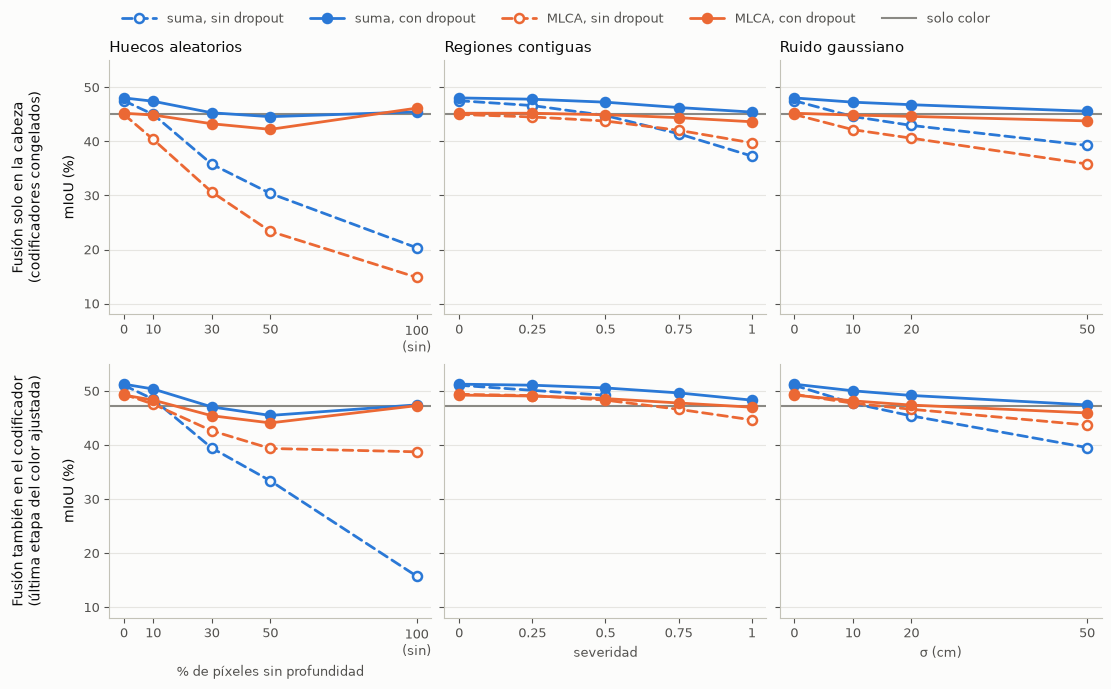

In [4]:
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TINTA, TINTA2, EJE, REJILLA, FONDO = "#0b0b0b", "#52514e", "#c3c2b7", "#e6e5e1", "#fcfcfb"

TEXTOS = {
    "es": {"filas": ["Fusión solo en la cabeza\n(codificadores congelados)",
                     "Fusión también en el codificador\n(última etapa del color ajustada)"],
           "cols": ["Huecos aleatorios", "Regiones contiguas", "Ruido gaussiano"],
           "x": ["% de píxeles sin profundidad", "severidad", "σ (cm)"], "sin": "100\n(sin)",
           "series": {("suma", False): "suma, sin dropout", ("suma", True): "suma, con dropout",
                      ("mlca", False): "MLCA, sin dropout", ("mlca", True): "MLCA, con dropout"},
           "ref": "solo color"},
    "en": {"filas": ["Fusion in the head only\n(frozen encoders)",
                     "Fusion also in the encoder\n(last RGB stage fine-tuned)"],
           "cols": ["Random holes", "Contiguous regions", "Gaussian noise"],
           "x": ["% of pixels without depth", "severity", "σ (cm)"], "sin": "100\n(none)",
           "series": {("suma", False): "sum, no dropout", ("suma", True): "sum, modality dropout",
                      ("mlca", False): "MLCA, no dropout", ("mlca", True): "MLCA, modality dropout"},
           "ref": "RGB only"},
}
FILAS_FIG = [("E1", [("E2c", "suma", False), ("E2cd", "suma", True), ("E4c", "mlca", False), ("E4cd", "mlca", True)]),
             ("E1u", [("E11", "suma", False), ("E11d", "suma", True), ("E4e", "mlca", False), ("E4ed", "mlca", True)])]
EJES_X = [([0, 10, 30, 50, 100], ["completa", "aleatoria_10", "aleatoria_30", "aleatoria_50", "sin"]),
          ([0, 0.25, 0.5, 0.75, 1.0], ["completa", "regiones_025", "regiones", "regiones_075", "regiones_100"]),
          ([0, 10, 20, 50], ["completa", "ruido_10cm", "ruido_20cm", "ruido_50cm"])]


def estilo(op, drop):
    color = AZUL if op == "suma" else NARANJA
    return dict(color=color, lw=2, ls="-" if drop else (0, (3.5, 2)), marker="o", ms=6.5, mec=color, mew=1.8,
                mfc=color if drop else FONDO, solid_capstyle="round", dash_capstyle="round")


def figura_robustez(idioma, ruta=None):
    t = TEXTOS[idioma]
    fig, ejes = plt.subplots(2, 3, figsize=(11, 6.8), sharey=True, facecolor=FONDO, layout="constrained")
    for i, (ref, modelos) in enumerate(FILAS_FIG):
        for j, (xs, conds) in enumerate(EJES_X):
            ax = ejes[i, j]
            ax.set_facecolor(FONDO)
            ax.axhline(m(ref), color=GRIS, lw=1.5, zorder=1)
            for exp, op, drop in modelos:
                pts = [(x, m(exp, c)) for x, c in zip(xs, conds) if not np.isnan(m(exp, c))]
                ax.plot(*zip(*pts), zorder=3, **estilo(op, drop))
            ax.set_xticks(xs)
            ax.set_xticklabels([t["sin"] if (j == 0 and x == 100) else f"{x:g}" for x in xs])
            ax.set_ylim(8, 55)
            ax.set_yticks([10, 20, 30, 40, 50])
            ax.yaxis.grid(True, color=REJILLA, lw=0.8)
            ax.set_axisbelow(True)
            for lado in ("top", "right"):
                ax.spines[lado].set_visible(False)
            for lado in ("left", "bottom"):
                ax.spines[lado].set_color(EJE)
            ax.tick_params(colors=TINTA2, labelsize=9)
            if i == 0:
                ax.set_title(t["cols"][j], loc="left", fontsize=11, color=TINTA)
            if i == 1:
                ax.set_xlabel(t["x"][j], color=TINTA2, fontsize=9.5)
            if j == 0:
                ax.set_ylabel(t["filas"][i] + "\n\nmIoU (%)", color=TINTA, fontsize=10)
    claves = [((op, drop), estilo(op, drop)) for op in ("suma", "mlca") for drop in (False, True)]
    manijas = [Line2D([], [], **e) for _, e in claves] + [Line2D([], [], color=GRIS, lw=1.5)]
    nombres = [t["series"][k] for k, _ in claves] + [t["ref"]]
    fig.legend(manijas, nombres, loc="outside upper center", ncol=5, frameon=False, fontsize=9.5,
               labelcolor=TINTA2, handlelength=2.6)
    if ruta is not None:
        fig.savefig(ruta, dpi=200, facecolor=FONDO)
    return fig


figura_robustez("en", RAIZ / "proposal" / "figs" / "robustez_d06_d07_en.png")
plt.close()
figura_robustez("es", RAIZ / "notebooks" / "figs" / "12_1_robustez.png")
plt.show()

**Figura 1.** mIoU frente a la degradación de la profundidad (test, media de 3 semillas). Arriba, la fusión solo
en la cabeza; abajo, también a la entrada de la última etapa del color. Azul, suma; naranja, MLCA con máscara;
discontinua y marcador vacío, sin dropout; continua y marcador lleno, con dropout; gris, solo color (E1 arriba, E1u
abajo). Sin dropout, todas caen al degradarse la profundidad, y en el codificador la MLCA cae mucho menos que la suma.
Con dropout, con el 50 % de huecos aleatorios quedan entre 0.4 y 3.2 por debajo de solo color, y sin profundidad, a
la par o hasta 1.2 por encima. Las regiones de severidad 0.25, 0.75 y 1.0 no se evaluaron en E11, una corrida de la
v3. La versión en inglés, para el póster, está en `proposal/figs/robustez_d06_d07_en.png`.

## 5. Criterio estadístico (registrado antes de abrir los resultados)

Diferencias pareadas por imagen, IC 95 % por remuestreo de imágenes con Holm sobre las condiciones de cada
contraste (`tools/criterio_d06.py`; salidas guardadas en `runs/rgbd/criterio_d06.txt` y `criterio_d07.txt`). E11 y E1u
son corridas de la v3 sin métricas por imagen: sus contrastes solo tienen las medias y el signo por semilla
(sección 3).

In [5]:
PATRON = re.compile(r"^\s+(\S+)\s+([+-]\d+\.\d+)\s+IC \(Holm\) \[([+-]\d+\.\d+), ([+-]\d+\.\d+)\]\s+"
                    r"semillas\s+(.+?)\s+p Holm\s+(\S+)\s+→\s+(.+)$")


def leer_criterio(ruta, decision):
    filas, contraste = [], None
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        if " − " in linea and not linea.startswith(" "):
            contraste = linea.strip()
        elif (mt := PATRON.match(linea)) and contraste:
            cond, dif, lo, hi, semillas, p, veredicto = mt.groups()
            filas.append({"D": decision, "contraste": contraste, "condición": cond, "dif.": dif,
                          "IC 95 % (Holm)": f"[{lo}, {hi}]", "semillas": semillas, "veredicto": veredicto})
    return filas


crit = pd.DataFrame(leer_criterio(RUNS / "criterio_d06.txt", "D-06") + leer_criterio(RUNS / "criterio_d07.txt", "D-07"))
L = ["| D | Contraste | Condición | Dif. | IC 95 % (Holm) | Semillas | Veredicto |", "|---|---|---|---|---|---|---|"]
for _, f in crit.iterrows():
    v = f["veredicto"]
    L.append(f"| {f['D']} | {f['contraste']} | {f['condición']} | {f['dif.']} | {f['IC 95 % (Holm)']} | "
             f"{f['semillas']} | {'**' + v + '**' if v in ('aporta', 'perjudica') else v} |")
display(Markdown("\n".join(L)))

| D | Contraste | Condición | Dif. | IC 95 % (Holm) | Semillas | Veredicto |
|---|---|---|---|---|---|---|
| D-06 | E4c − E3c | cruda | -0.63 | [-1.03, -0.24] | -0.62 -0.86 -0.41 | **perjudica** |
| D-06 | E4c − E3c | regiones | +0.63 | [+0.45, +0.79] | +0.62 +0.94 +0.31 | **aporta** |
| D-06 | E4c − E3c | sin | +1.15 | [+0.70, +1.58] | -1.13 +10.67 -6.10 | no concluyente |
| D-06 | E4cd − E3cd | cruda | +0.01 | [-0.42, +0.45] | +0.01 -0.17 +0.18 | no aporta |
| D-06 | E4cd − E3cd | regiones | -0.21 | [-0.64, +0.22] | -0.51 +0.23 -0.35 | no aporta |
| D-06 | E4cd − E3cd | sin | +0.85 | [+0.37, +1.34] | +0.80 +0.81 +0.93 | **aporta** |
| D-06 | E3cd − E3c | cruda | +3.71 | [+2.93, +4.45] | +3.83 +3.37 +3.94 | **aporta** |
| D-06 | E3cd − E3c | regiones | +2.00 | [+1.38, +2.61] | +2.11 +1.58 +2.30 | **aporta** |
| D-06 | E3cd − E3c | sin | +31.60 | [+30.40, +32.62] | +28.59 +37.25 +28.96 | **aporta** |
| D-06 | E4cd − E4c | cruda | +4.35 | [+3.54, +5.12] | +4.47 +4.06 +4.52 | **aporta** |
| D-06 | E4cd − E4c | regiones | +1.16 | [+0.59, +1.72] | +0.98 +0.87 +1.63 | **aporta** |
| D-06 | E4cd − E4c | sin | +31.30 | [+29.84, +32.55] | +30.51 +27.39 +35.99 | **aporta** |
| D-06 | E3c − E2c | cruda | -2.12 | [-2.95, -1.27] | -2.57 -2.13 -1.67 | **perjudica** |
| D-06 | E3c − E2c | regiones | -1.65 | [-2.34, -0.89] | -1.40 -1.48 -2.06 | **perjudica** |
| D-06 | E3c − E2c | sin | -6.62 | [-7.17, -5.96] | -5.11 -9.70 -5.06 | **perjudica** |
| D-07 | E4e − E3e | completa | +0.00 | [+0.00, +0.00] | +0.00 +0.00 +0.00 | no aporta |
| D-07 | E4e − E3e | cruda | +0.10 | [-0.07, +0.26] | +0.14 +0.06 +0.10 | no aporta |
| D-07 | E4e − E3e | regiones | +0.15 | [+0.04, +0.28] | +0.31 +0.13 +0.03 | **aporta** |
| D-07 | E4e − E3e | sin | +9.39 | [+8.45, +10.32] | +12.49 +7.80 +7.88 | **aporta** |
| D-07 | E4ed − E11d | completa | -2.02 | [-2.74, -1.31] | -1.84 -1.93 -2.30 | **perjudica** |
| D-07 | E4ed − E11d | cruda | -1.92 | [-2.64, -1.22] | -1.47 -2.15 -2.15 | **perjudica** |
| D-07 | E4ed − E11d | regiones | -1.97 | [-2.59, -1.36] | -1.73 -2.00 -2.19 | **perjudica** |
| D-07 | E4ed − E11d | sin | -0.14 | [-0.55, +0.31] | -0.16 -0.27 +0.00 | no aporta |
| D-07 | E2cd − E4cd | completa | +2.83 | [+2.21, +3.47] | +2.77 +2.90 +2.84 | **aporta** |
| D-07 | E2cd − E4cd | cruda | +2.75 | [+2.12, +3.32] | +2.62 +2.93 +2.69 | **aporta** |
| D-07 | E2cd − E4cd | regiones | +2.33 | [+1.77, +2.86] | +2.29 +2.26 +2.42 | **aporta** |
| D-07 | E2cd − E4cd | sin | -0.69 | [-0.91, -0.48] | -0.72 -0.61 -0.74 | **perjudica** |
| D-07 | E2cd − E2c | completa | +0.52 | [-0.08, +1.10] | +0.50 +0.29 +0.78 | no concluyente |
| D-07 | E2cd − E2c | cruda | +4.35 | [+3.60, +5.14] | +3.90 +4.00 +5.14 | **aporta** |
| D-07 | E2cd − E2c | regiones | +2.47 | [+1.77, +3.18] | +2.49 +2.59 +2.31 | **aporta** |
| D-07 | E2cd − E2c | sin | +25.14 | [+23.84, +26.34] | +23.56 +27.76 +24.09 | **aporta** |

## 6. Por qué: lo que suma cada fusión a los rasgos de color

Diagnósticos de D-06 (exploratorios: validación por escenas, semilla 0, fusión en la cabeza). Δ es lo que la fusión
suma al rasgo de color en cada escala. «Parte que varía con la posición»: fracción de Δ que no es constante en la
imagen; «tamaño»: norma de Δ frente a la del rasgo de color. Las dos últimas columnas, el mIoU de validación al quitar Δ.

In [6]:
diag = json.loads((RUNS / "diagnosticos_d06_validacion.json").read_text(encoding="utf-8"))
ESC = ("1/8", "1/16", "1/32")
L = ["| Exp. | Parte de Δ que varía con la posición (1/8 · 1/16 · 1/32) | Tamaño de Δ frente al color | mIoU | sin Δ en 1/32 | sin Δ en todas |",
     "|---|---|---|---|---|---|"]
for e in ("E2c", "E4c", "E4cd"):
    c = diag[e][0]["por_dentro"]["completa"]
    L.append(f"| {e} | " + " · ".join(f"{c['parte_no_constante'][s]:.2f}" for s in ESC) + " | "
             + " · ".join(f"{c['relativo'][s]:.2f}" for s in ESC)
             + f" | {c['miou']['ninguna']:.2f} | {c['miou']['sin_1/32']:.2f} | {c['miou']['sin_todas']:.2f} |")
display(Markdown("\n".join(L)))

| Exp. | Parte de Δ que varía con la posición (1/8 · 1/16 · 1/32) | Tamaño de Δ frente al color | mIoU | sin Δ en 1/32 | sin Δ en todas |
|---|---|---|---|---|---|
| E2c | 0.86 · 0.78 · 0.79 | 0.55 · 0.96 · 0.65 | 46.38 | 41.62 | 37.44 |
| E4c | 0.41 · 0.56 · 0.28 | 0.67 · 0.86 · 1.35 | 43.18 | 13.76 | 9.28 |
| E4cd | 0.93 · 0.99 · 0.97 | 0.16 · 0.30 · 0.46 | 43.36 | 43.60 | 43.50 |

- **Por qué la MLCA aprovecha menos una profundidad buena.** La atención lineal resume toda la imagen en
  S = Σⱼ mⱼ φ(kⱼ) vⱼᵀ, y cada posición lee ese mismo resumen ponderado por su consulta. Lo que suma varía poco con la
  posición: en E4c, entre el 28 y el 56 % de Δ, frente al 78-86 % de la suma (E2c), que agrega en cada posición la
  profundidad de esa posición.
- **Por qué, sin dropout, también se degrada menos en el codificador** (interpretación: no hay diagnósticos del
  codificador). El mismo resumen promedia sobre toda la imagen, así que un 50 % de huecos o ruido de 50 cm lo cambian
  menos que a los valores de cada posición (sección 3, punto 2).
- **Por qué colapsa en la cabeza sin dropout.** En 1/32, el Δ de E4c mide 1.35 veces el rasgo de color: la cabeza
  depende de él. Quitarlo, o que la máscara lo apague sin profundidad, la hunde de 43.18 a 13.76.
- **Por qué el dropout lo arregla.** Con dropout, Δ es pequeño (0.16-0.46 del rasgo de color) y quitarlo no cambia
  nada (43.36 → 43.50): la cabeza aprendió a no depender de la fusión. Por eso E4cd queda casi igual que solo color con
  profundidad completa (+0.22 sobre E1).

## 7. Costo (RTX 4060 Laptop, bf16, lote 1, 480×640)

`python src/coste.py --exps E1u E2c E4c E10 E11 E11d E4e E4ed --sufijo _d07`. Los pesos no cambian el costo, así que
cada fila vale también para las variantes que solo cambian el entrenamiento o la máscara.

In [7]:
coste = json.loads((RAIZ / "runs" / "coste" / "coste_cuda_bf16_d07.json").read_text(encoding="utf-8"))
MISMO = {"E1u": "E1", "E2c": "E2cd", "E4c": "E3c, E3cd, E4cd", "E11": "", "E11d": "", "E4e": "E3e", "E4ed": ""}
L = ["| Exp. | Mismo costo que | Parámetros (M) | Entrenables (M) | GFLOPs | de ellos, DeFM | de ellos, fusión | Latencia (ms) | VRAM pico (MiB) |",
     "|---|---|---|---|---|---|---|---|---|"]
for e, r in coste["experimentos"].items():
    pf = r["flops_por_parte"]
    L.append(f"| {e} | {MISMO.get(e, '')} | {r['parametros'] / 1e6:.2f} | {r['entrenables'] / 1e6:.2f} | "
             f"{r['flops'] / 1e9:.2f} | {pf['defm'] / 1e9:.2f} | {pf['fusion'] / 1e9:.2f} | "
             f"{r['latencia_ms']:.1f} ± {r['latencia_de_ms']:.1f} | {r['vram_pico_mib']:.0f} |")
display(Markdown("\n".join(L)))

| Exp. | Mismo costo que | Parámetros (M) | Entrenables (M) | GFLOPs | de ellos, DeFM | de ellos, fusión | Latencia (ms) | VRAM pico (MiB) |
|---|---|---|---|---|---|---|---|---|
| E1u | E1 | 4.78 | 3.93 | 7.18 | 0.00 | 0.00 | 19.6 ± 1.3 | 53 |
| E2c | E2cd | 16.68 | 0.30 | 31.71 | 24.34 | 0.20 | 28.1 ± 2.5 | 132 |
| E4c | E3c, E3cd, E4cd | 17.00 | 0.62 | 32.20 | 24.34 | 0.69 | 30.8 ± 1.4 | 133 |
| E10 |  | 16.68 | 4.08 | 31.71 | 24.34 | 0.20 | 27.4 ± 1.4 | 139 |
| E11 |  | 16.69 | 4.10 | 31.75 | 24.34 | 0.24 | 27.6 ± 2.3 | 132 |
| E11d |  | 16.69 | 4.10 | 31.75 | 24.34 | 0.24 | 27.0 ± 1.0 | 132 |
| E4e | E3e | 16.74 | 4.15 | 31.89 | 24.34 | 0.37 | 27.8 ± 1.2 | 132 |
| E4ed |  | 16.74 | 4.15 | 31.89 | 24.34 | 0.37 | 28.7 ± 1.9 | 132 |

DeFM domina el costo: 24.3 de los ~31.8 GFLOPs y unos 7-11 ms sobre los ~19.6 ms de solo color. La fusión es
marginal: la MLCA añade 0.14 GFLOPs sobre la suma en el codificador (E4e frente a E11) y 0.49 en la cabeza (E4c
frente a E2c). Las diferencias de latencia entre variantes con fusión (27-31 ms) son del orden de su desviación. La
VRAM de la medición anterior (`coste_cuda_bf16.md`, D-06) incluía restos del modelo medido antes; esta la corrige.

## 8. Limitaciones

- **Un solo dominio.** NYUv2 (interiores, un sensor). La evaluación en otro dominio (Fase C; propuesta: SUN RGB-D, sin
  reentrenar) está pendiente.
- **Test ya usado.** D-03 a D-05 usaron el test para diagnósticos y decisiones, y la elección de los rasgos C3/P4/C5 se
  apoyó en ellos: los resultados de D-06 y D-07 son semiconfirmatorios.
- **lr con una semilla de validación.** Es ruidosa: en E4e, la validación quedó a la par del test, cuando en las demás
  queda entre 1.1 y 3.5 puntos por debajo.
- **Extractores.** Las variantes del codificador ajustan la última etapa del color; el resumen hablaba de extractores
  congelados.
- **Fallos simulados.** Salvo «cruda», los huecos y el ruido son sintéticos.
- **Sin bootstrap para E11 y E1u** (corridas de la v3 sin métricas por imagen): sus contrastes solo tienen medias y
  signos por semilla.
- **Predicciones.** El equipo escribió las suyas antes de E1, E2, E4 y E5; D-03 a D-05 se corrieron sin predicción
  registrada, a pedido del equipo. En D-06 y D-07 hacen de registro previo las de la IA, escritas antes de cada
  lanzamiento (`predicciones/`).
- **Fuera de alcance.** E6 (atención softmax enmascarada, como UCTNet) no se implementó; E3ed (la máscara con dropout
  en el codificador) no se corrió. La combinación de dos modelos (E1u + E11, 52.21) duplica el cómputo y su ventaja
  sobre E11d es del tamaño de promediar dos modelos de solo color (+1.22), así que no entra en las conclusiones.

## Anexo A · Barrido de lr (validación por escenas, semilla 0, profundidad completa)

En negrita, la lr elegida (la mejor de la validación en todos los casos).

In [8]:
val = []
for f in sorted(RUNS.glob("val_*/resultado.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    val.append({"exp": r["exp"], "lr": r["lr"], "miou": r["resultados"]["completa"]["miou"]})
val = pd.DataFrame(val)
EXPS = [e for _, filas in GRUPOS for e, _ in filas]
LRS = sorted(val[val.exp.isin(EXPS)].lr.unique())
L = ["| Exp. | " + " | ".join(f"{x:g}" for x in LRS) + " |", "|---|" + "---|" * len(LRS)]
for e in EXPS:
    v = val[val.exp == e].set_index("lr").miou
    celdas = [("" if x not in v.index else (f"**{v[x]:.2f}**" if x == LR[e] else f"{v[x]:.2f}")) for x in LRS]
    assert v.idxmax() == LR[e], e
    L.append(f"| {e} | " + " | ".join(celdas) + " |")
display(Markdown("\n".join(L)))
brecha = {e: m(e) - val[(val.exp == e) & (val.lr == LR[e])].miou.iloc[0] for e in EXPS}
print("test − validación con la lr elegida:", ", ".join(f"{e} {b:+.2f}" for e, b in brecha.items()))

| Exp. | 0.0001 | 0.0003 | 0.001 | 0.003 | 0.01 |
|---|---|---|---|---|---|
| E1 |  | 43.38 | **43.43** | 41.98 |  |
| E2c |  | 45.94 | 45.78 | **46.38** | 45.04 |
| E3c |  | 42.37 | 42.15 | **43.18** | 42.86 |
| E4c |  | 42.37 | 42.15 | **43.18** | 42.86 |
| E2cd | 44.67 | **45.62** | 45.05 | 45.56 |  |
| E3cd |  | 43.36 | **43.68** | 43.40 |  |
| E4cd | 43.01 | **43.36** | 42.46 | 43.00 |  |
| E1u |  | 43.87 | **45.47** | 43.14 |  |
| E10 |  | 45.45 | **46.76** | 46.41 |  |
| E11 |  | 47.13 | 47.05 | **48.62** | 42.97 |
| E3e |  | 46.24 | **49.42** | 47.83 |  |
| E4e |  | 46.24 | **49.42** | 47.83 |  |
| E11d |  | 47.02 | **47.76** | 47.61 |  |
| E4ed |  | 45.55 | **47.10** | 39.39 |  |

test − validación con la lr elegida: E1 +1.56, E2c +1.15, E3c +1.81, E4c +1.81, E2cd +2.43, E3cd +1.77, E4cd +1.86, E1u +1.84, E10 +2.48, E11 +2.44, E3e -0.03, E4e -0.03, E11d +3.51, E4ed +2.14


## Anexo B · Qué clases ganan con la profundidad (E11d − E1u, completa)

In [9]:
def iou_por_clase(exp, cond="completa"):
    v = res[(res.exp == exp) & (res.cond == cond)].iou_clase
    return np.mean(np.stack([np.asarray(x, float) for x in v]), axis=0)


base, mejor = iou_por_clase("E1u"), iou_por_clase("E11d")
dif = mejor - base
orden = np.argsort(dif)[::-1]
L = ["| Clase | E1u | E11d | Dif. |", "|---|---|---|---|"]
for i in list(orden[:8]) + list(orden[-5:]):
    L.append(f"| {CLASES[i]} | {base[i]:.1f} | {mejor[i]:.1f} | {dif[i]:+.1f} |")
display(Markdown("\n".join(L)))
print(f"clases que pierden más de 0.5: {int((dif < -0.5).sum())} de {len(dif)}")

| Clase | E1u | E11d | Dif. |
|---|---|---|---|
| bathtub | 48.3 | 60.7 | +12.4 |
| whiteboard | 40.1 | 47.6 | +7.5 |
| floor mat | 42.6 | 50.1 | +7.5 |
| mirror | 52.9 | 60.2 | +7.3 |
| night stand | 46.2 | 53.2 | +7.0 |
| chair | 59.9 | 66.6 | +6.8 |
| pillow | 39.4 | 45.7 | +6.3 |
| shower curtain | 47.8 | 53.9 | +6.0 |
| picture | 60.0 | 61.1 | +1.1 |
| paper | 25.6 | 26.6 | +0.9 |
| door | 45.2 | 45.6 | +0.4 |
| otherstructure | 33.0 | 33.1 | +0.0 |
| books | 30.5 | 30.4 | -0.1 |

clases que pierden más de 0.5: 0 de 40


La profundidad ayuda en casi todas las clases. Lo que más gana son objetos que se reconocen por su forma (bañera,
mesa de noche, silla, almohada) y superficies donde el color engaña (espejo, pizarra).

## Anexo C · Los demás experimentos (exploratorios)

Historia previa a D-06: los de la v3 (E2, E4, E5, con rasgos de DeFM en los que solo P4 depende de la entrada),
las ablaciones de la máscara fraccional y las alternativas de D-03 y D-04. Definiciones en `DECISIONES.md`.

In [10]:
OTROS = [("E2", "suma, rasgos P3-P5 (v3)"), ("E4", "MLCA con máscara fraccional, rasgos P3-P5 (v3)"),
         ("E5", "E4 + dropout 0.3 (v3)"), ("E4cf", "E4c con máscara fraccional"),
         ("E4cfd", "E4cd con máscara fraccional"), ("E2h", "E2 entrenada con huecos (control de E8)"),
         ("E8", "respaldo en la salida: experto de color y de fusión con compuerta"),
         ("E2u", "E2 con la última etapa del color ajustada"),
         ("E7", "E1u + cabeza auxiliar de profundidad (no usa profundidad al inferir)"),
         ("E9", "E8 con el experto de color fijo (= E1u)")]
L = ["| Exp. | Qué es | lr | completa | cruda | 50 % aleatorio | sin profundidad |", "|---|---|---|---|---|---|---|"]
for e, que in OTROS:
    L.append(f"| {e} | {que} | {LR[e]:g} | " + " | ".join(mde(e, c) for c in ("completa", "cruda", "aleatoria_50", "sin")) + " |")
display(Markdown("\n".join(L)))

| Exp. | Qué es | lr | completa | cruda | 50 % aleatorio | sin profundidad |
|---|---|---|---|---|---|---|
| E2 | suma, rasgos P3-P5 (v3) | 0.0003 | 47.31 ± 0.26 | 46.97 ± 0.52 | 43.90 ± 0.12 | 42.25 ± 0.45 |
| E4 | MLCA con máscara fraccional, rasgos P3-P5 (v3) | 0.0003 | 45.24 ± 0.29 | 45.04 ± 0.19 | 41.89 ± 1.40 | 0.78 ± 1.22 |
| E5 | E4 + dropout 0.3 (v3) | 0.0003 | 45.48 ± 0.21 | 45.45 ± 0.20 | 44.25 ± 0.73 | 45.74 ± 0.10 |
| E4cf | E4c con máscara fraccional | 0.003 | 44.99 ± 0.20 | 40.44 ± 0.21 | 22.97 ± 4.19 | 14.86 ± 4.18 |
| E4cfd | E4cd con máscara fraccional | 0.0003 | 45.21 ± 0.33 | 44.93 ± 0.59 | 42.28 ± 1.80 | 46.16 ± 0.26 |
| E2h | E2 entrenada con huecos (control de E8) | 0.001 | 46.98 ± 0.22 | 46.63 ± 0.30 | 43.95 ± 0.27 | 44.59 ± 0.20 |
| E8 | respaldo en la salida: experto de color y de fusión con compuerta | 0.003 | 48.17 ± 0.33 | 47.08 ± 0.35 | 45.11 ± 0.35 | 44.00 ± 0.29 |
| E2u | E2 con la última etapa del color ajustada | 0.003 | 48.59 ± 0.15 | 47.71 ± 0.41 | 43.90 ± 0.12 | 36.84 ± 0.70 |
| E7 | E1u + cabeza auxiliar de profundidad (no usa profundidad al inferir) | 0.001 | 47.28 ± 0.54 | 47.28 ± 0.54 | 47.28 ± 0.54 | 47.28 ± 0.54 |
| E9 | E8 con el experto de color fijo (= E1u) | 0.0003 | 47.76 ± 0.09 | 47.72 ± 0.09 | 47.57 ± 0.09 | 47.31 ± 0.10 |